In [1]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from dotenv import load_dotenv



load_dotenv()

embeddings_own = OpenAIEmbeddings(model="text-embedding-3-large")
store = InMemoryVectorStore(embeddings_own)



with open("rules.txt", "r", encoding="utf-8") as file:
    text = file.read()

chunks = text.split("\n\n\n")
docs = []
for i in chunks:
    docs.append(Document(i, metadata={"source": "rules.txt"}))



some_document = docs
store.store.clear()
store.add_documents(documents=some_document)

['db3006df-16f4-4440-913b-7c8c3183cc77',
 '3402f926-a863-4599-ba27-94bc77080824',
 'be33a47c-70ab-4003-91da-0a1b51b24164',
 '6555c1f9-0277-4e30-9603-09b318662ddc',
 'cbae4733-8dd7-445b-8da7-21f447710109',
 '59644ec9-6141-4452-8067-fd0264d1ba2c',
 '5049f992-2578-4dbf-9187-f2402bd4d592',
 '5bed32b1-c360-4cf6-a032-a467e6435aed',
 'aff276c3-f4e1-4c98-a534-f0cc8eff5014',
 '80c77e27-ff3f-41db-937f-437f9af3736c']

In [7]:
from langgraph.graph import START, StateGraph, MessagesState, END
from IPython.display import display, Image
import pandas
from langchain_core.documents import Document
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langchain.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition
from typing import Literal

class MessagesState(MessagesState):
    new_data_frame: pandas.DataFrame
    i: int
    attribute: str
    value: str

def start_node(state: MessagesState) -> MessagesState:
    if (data_frame.shape[0] - 1 > state["i"]):
        state["attribute"] = data_frame.iloc[state["i"]]["Attribute"]
        state["value"] = data_frame.iloc[state["i"]]["Value"]
    return state;

def llm_node(state: MessagesState) -> Literal["retrieve_context", "end_node"]:
    if state["i"] < data_frame.shape[0] - 1:
        return "retrieve_context"
    else:
        return "end_node"
    # return {"messages": [llm_with_tools.invoke(state.get("messages"))]}

SYSTEM_PROMPT = """you are helpful assistant for searching information, and you have to '{Value}' in accordance with the rules for the specified '{Attribute}'"""

def retrieve_context(state: MessagesState) -> MessagesState:
    """Retrieve information to help answer a query and return list of documents."""
    retrived_documents = store.similarity_search(query=state.get("attribute"), k=2)
    contexts = "\n\n".join(f"{doc.page_content}" for doc in retrived_documents)
    # print(f"Retrieved documents: {retrived_documents}\n\n\nContext documents: {contexts}")
    new_iteration = state.get("i") + 1
    inv = model.invoke([{"role": "system", "content": SYSTEM_PROMPT}, {"role": 'user', "content": f"Attribute: {state['attribute']}\nValue: {state['value']}\n\nRelevant rules:\n{contexts}"}])

    new_row = pandas.DataFrame([{"Attribute": state["attribute"],
                                 "Value": state["value"],
                                 "Rules_Value": inv.content}])

    updated_data_frame = pandas.concat([state["new_data_frame"], new_row], ignore_index=True)

    return {"messages": [inv], "i": new_iteration, "new_data_frame": updated_data_frame}

def end_node(state: MessagesState) -> MessagesState:
    file = state.get("new_data_frame")
    file.to_excel("first_phase_table1.xlsx", index=False)
    return state

load_dotenv()


data_frame = pandas.read_excel("attributes.xlsx")

# tools = [retrieve_context]
# tools_node = ToolNode(tools)

model = ChatOpenAI(model="gpt-4o", temperature=0)
# llm_with_tools = model.bind_tools(tools)

builder = StateGraph(MessagesState)
builder.add_node(start_node)
builder.add_node(retrieve_context)
builder.add_node(end_node)
builder.add_edge(START, "start_node")
builder.add_conditional_edges("start_node", llm_node)
builder.add_edge("retrieve_context", "start_node")
builder.add_edge("end_node", END)

graph = builder.compile()

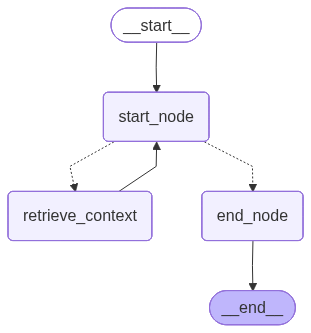

In [4]:
display(Image(graph.get_graph().draw_mermaid_png()))

In [5]:
data_frame = pandas.read_excel("attributes.xlsx")
data_frame

,Attribute,Value
0,Valve type,"Gate valve, wedge"
1,"Nominal diameter, mm",100
2,"Nominal pressure, MPa",1.6
3,Working medium,"Water, steam"
4,"Working medium temperature, C",120
5,Body material,Grey cast iron GG-20
6,Seal material,Stainless steel 12Cr18Ni9Ti
7,Actuator type,Manual handwheel
8,"Face-to-face length, mm",250
9,"Weight, kg",18.5


In [8]:
result = graph.invoke({"messages": [], 'new_data_frame': pandas.DataFrame(columns=["Attribute", "Value", "Rules_Value"]), "i":0})

for f in result["messages"]:
    f.pretty_print()

================================== Ai Message ==================================

Gate valves with a wedge design must adhere to specific leakage and connection standards to ensure proper functionality and safety. According to the relevant rules:

1. **Leakage Class**: The valve must meet the leakage class specified in its documentation. For steam and gas applications, Class A, which denotes zero leakage, is required. For water service, Class B is acceptable.

2. **End Connection Type**: The end connection type of the valve must match the pressure class and nominal diameter. For valves with a nominal diameter (DN) of 50 mm and above, and a pressure nominal (PN) of 1.0 MPa or higher, flanged connections are mandatory.

3. **Flange Geometry**: The flange geometry must comply with the standards set by GOST 33259-2015, which has replaced the earlier GOST 12815-80 standard.

These requirements ensure that the gate valve with a wedge design is suitable for its intended application and meets 